# 03 · Líneas base y modelos candidatos

Se entrenan dos líneas base y cuatro familias de modelos con sus hiperparámetros por defecto, más una prueba con un LLM. Todos usan **la misma preparación** (`construir_preparacion()` de `src/pipeline.py`), **la misma división** y **la misma métrica**.

- **Métrica técnica: PR-AUC** (`average_precision`). Mide qué tan arriba ubica el modelo a los créditos que sí pagan. Se elige porque el target está desbalanceado (18.67% de positivos): la accuracy premiaría a un modelo que dice siempre "no paga".
- **Validación:** validación cruzada **por crédito** (`GroupKFold`, 5 pliegues) dentro del entrenamiento: cada crédito queda completo en un solo pliegue, para que el modelo no pueda reconocerlo y copiar su respuesta (ver el diagnóstico de la sección 3). El conjunto de prueba (21 al 24 de octubre) no se usa aquí: se usa una sola vez, en `05_seleccion`.

Cada corrida queda registrada en MLflow, en el experimento `priorizacion-cartera`.

## 1. Datos, huella y experimento

In [1]:
import sys
sys.path.append("..")

import logging
import subprocess
import time
import warnings

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
from scipy.optimize import OptimizeWarning
from sklearn.exceptions import ConvergenceWarning
from src.datos import TABLA, huella
from src.pipeline import (FIN_ENTRENAMIENTO, INICIO_PRUEBA,
                          cargar_y_dividir, construir_preparacion)

logging.getLogger("mlflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module="mlflow")
warnings.filterwarnings("ignore", category=OptimizeWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="The groups parameter is ignored")

X_ent, X_prueba, y_ent, y_prueba, grupos_ent = cargar_y_dividir()
huella_datos = huella(pd.concat([X_ent, y_ent], axis=1))
commit = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"]).decode().strip()

mlflow.set_experiment("priorizacion-cartera")

print("Registro de MLflow:", mlflow.get_tracking_uri())
print("Entrenamiento:", X_ent.shape, "| Prueba:", X_prueba.shape)
print("Huella de los datos:", huella_datos, "| Commit:", commit)

Registro de MLflow: http://localhost:5000
Entrenamiento: (36674, 18) | Prueba: (12553, 18)
Huella de los datos: 51a0dd5e8d2d | Commit: 5638b45


## 2. Validación cruzada por crédito y registro en MLflow

`evaluar()` hace lo mismo con cada modelo, para que la comparación sea justa:
1. Arma el pipeline: la preparación de `src/pipeline.py` + el modelo.
2. Hace la validación cruzada **por crédito** (5 pliegues, ver sección 3) en el entrenamiento y guarda la PR-AUC de cada pliegue.
3. Entrena con todo el entrenamiento, mide la PR-AUC en entrenamiento y los segundos que tardó.
4. Registra en MLflow: hiperparámetros, datos (tabla de origen, fechas de corte de la división y huella), métricas, tags (fase, familia y commit) y el pipeline entrenado con su firma y un ejemplo de entrada.

**Brecha = PR-AUC en entrenamiento − PR-AUC promedio en CV.** Una brecha grande indica sobreajuste: el modelo memoriza el entrenamiento y rinde peor en créditos que no vio.

In [2]:
from mlflow.models import infer_signature
from sklearn.metrics import average_precision_score
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline

CV = GroupKFold(n_splits=5)
resultados = []


def evaluar(nombre, modelo, familia, fase="candidato"):
    pipeline = Pipeline([("preparar", construir_preparacion()), ("modelo", modelo)])

    with mlflow.start_run(run_name=nombre):
        mlflow.log_params(modelo.get_params())
        mlflow.log_params({"semilla": 42, "tabla_origen": TABLA, "fin_entrenamiento": FIN_ENTRENAMIENTO,
                           "inicio_prueba": INICIO_PRUEBA, "huella_datos": huella_datos,
                           "filas_entrenamiento": len(X_ent), "validacion": "GroupKFold(5) por credito"})
        mlflow.set_tags({"fase": fase, "familia": familia, "commit": commit})

        cv = cross_validate(pipeline, X_ent, y_ent, cv=CV, groups=grupos_ent, scoring="average_precision")

        inicio = time.perf_counter()
        pipeline.fit(X_ent, y_ent)
        segundos = time.perf_counter() - inicio
        pr_auc_ent = average_precision_score(y_ent, pipeline.predict_proba(X_ent)[:, 1])

        metricas = {"pr_auc_entrenamiento": pr_auc_ent,
                    "pr_auc_cv_promedio": cv["test_score"].mean(),
                    "pr_auc_cv_desviacion": cv["test_score"].std(),
                    "brecha": pr_auc_ent - cv["test_score"].mean(),
                    "segundos_entrenamiento": segundos}
        for i, valor in enumerate(cv["test_score"]):
            metricas[f"pr_auc_pliegue_{i + 1}"] = valor
        mlflow.log_metrics(metricas)

        firma = infer_signature(X_ent.head(100), pipeline.predict_proba(X_ent.head(100))[:, 1])
        mlflow.sklearn.log_model(pipeline, "modelo", signature=firma, input_example=X_ent.head(5))

    resultados.append({"modelo": nombre, "familia": familia, **metricas})
    print(f"{nombre:25s} entrenamiento {pr_auc_ent:.4f} | CV {metricas['pr_auc_cv_promedio']:.4f} "
          f"± {metricas['pr_auc_cv_desviacion']:.4f} | {segundos:.1f} s")

## 3. Diagnóstico: ¿qué esquema de validación cruzada corresponde a estos datos?

El mismo crédito aparece en días consecutivos con casi los mismos datos, y su target se repite (un pago marca como positivos los 7 cortes anteriores). Si un crédito está en el entrenamiento y en la validación de un mismo pliegue, un modelo puede **reconocerlo y copiar su respuesta**, usando targets que en producción todavía no se conocerían. Se comparan tres esquemas:
- **Temporal** (`TimeSeriesSplit`): entrena con días anteriores y valida con días posteriores.
- **Por crédito** (`GroupKFold`): cada crédito queda completo en un solo pliegue.
- **Aleatorio** (`KFold` con mezcla): referencia.

Este diagnóstico no se registra en MLflow.

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score

esquemas = {"temporal": TimeSeriesSplit(n_splits=5),
            "por credito": GroupKFold(n_splits=5),
            "aleatorio": KFold(n_splits=5, shuffle=True, random_state=42)}
modelos = {"regresion logistica": LogisticRegression(max_iter=1000, random_state=42),
           "random forest": RandomForestClassifier(random_state=42, n_jobs=-1)}

filas = []
for nombre_modelo, modelo in modelos.items():
    for nombre_esquema, esquema in esquemas.items():
        pipeline = Pipeline([("preparar", construir_preparacion()), ("modelo", modelo)])
        notas = cross_val_score(pipeline, X_ent, y_ent, cv=esquema, groups=grupos_ent,
                                scoring="average_precision")
        filas.append({"modelo": nombre_modelo, "esquema": nombre_esquema,
                      "promedio": round(notas.mean(), 4), "desviacion": round(notas.std(), 4)})
pd.DataFrame(filas)

,modelo,esquema,promedio,desviacion
0,regresion logistica,temporal,0.4415,0.0494
1,regresion logistica,por credito,0.4453,0.0265
2,regresion logistica,aleatorio,0.4496,0.0139
3,random forest,temporal,0.8423,0.0696
4,random forest,por credito,0.4132,0.0220
5,random forest,aleatorio,0.9429,0.0054


**Hallazgo: la validación temporal y la aleatoria son optimistas porque el modelo reconoce al mismo crédito.**
- **Evidencia:** el Random Forest obtiene PR-AUC de 0.842 con validación temporal y 0.943 con aleatoria, pero 0.413 cuando cada crédito queda completo en un solo pliegue (por crédito). La regresión logística, que no puede memorizar créditos, obtiene casi lo mismo en los tres esquemas (0.442 a 0.450).
- **Causa:** el mismo crédito aparece en días consecutivos con datos casi idénticos (monto financiado, tasa, cuotas) y el mismo target, porque un pago marca como positivos los 7 cortes anteriores. Un modelo flexible lo reconoce en la validación y copia una respuesta que, en producción, todavía no se conocería.
- **Consecuencia:** la validación cruzada se hace **por crédito** (`GroupKFold`, 5 pliegues). No se usa la temporal con una brecha de 7 días porque con 13 días de entrenamiento no alcanzan los días para entrenar, dejar la brecha y validar. La evaluación final sí es temporal, con brecha: entrenamiento hasta el 13 de octubre y prueba del 21 al 24. El esquema aleatorio se reporta como comparación.

## 4. Línea base ingenua

`DummyClassifier(strategy="prior")` predice para todos los créditos la misma probabilidad: la proporción de pago del entrenamiento. No ordena a nadie, así que su PR-AUC es aproximadamente esa proporción. Es el piso: cualquier modelo útil debe superarla.

In [4]:
from sklearn.dummy import DummyClassifier

evaluar("linea base ingenua", DummyClassifier(strategy="prior"), familia="linea base", fase="baseline")

linea base ingenua        entrenamiento 0.1565 | CV 0.1565 ± 0.0042 | 0.1 s


**Resultado:** la línea base ingenua obtiene PR-AUC de 0.157 en entrenamiento y 0.157 ± 0.004 en CV: exactamente la proporción de pago del entrenamiento (15.65%), porque no ordena a ningún crédito. Es el piso que todo modelo debe superar.

## 5. Línea base de negocio: "mayor capital insoluto primero"

Representa el orden actual dentro de la base que trabaja el cobrador (hallazgo del EDA, sección 12): se llama primero a los créditos con mayor capital insoluto, que es lo que mueve los indicadores PAR. No se entrena nada: el "puntaje" de cada crédito es su capital insoluto. Se evalúa con los mismos 5 pliegues y la misma métrica que los modelos. Como no hay un modelo entrenado, la corrida no guarda artefacto.

In [5]:
with mlflow.start_run(run_name="linea base negocio"):
    mlflow.log_params({"regla": "mayor capital insoluto primero", "semilla": 42, "tabla_origen": TABLA,
                       "fin_entrenamiento": FIN_ENTRENAMIENTO, "inicio_prueba": INICIO_PRUEBA,
                       "huella_datos": huella_datos, "filas_entrenamiento": len(X_ent),
                       "validacion": "GroupKFold(5) por credito"})
    mlflow.set_tags({"fase": "baseline", "familia": "regla de negocio", "commit": commit})

    pliegues = []
    for _, val in CV.split(X_ent, groups=grupos_ent):
        pliegues.append(average_precision_score(y_ent.iloc[val], X_ent["capital_insoluto"].iloc[val]))
    pliegues = np.array(pliegues)
    pr_auc_ent = average_precision_score(y_ent, X_ent["capital_insoluto"])

    metricas = {"pr_auc_entrenamiento": pr_auc_ent,
                "pr_auc_cv_promedio": pliegues.mean(),
                "pr_auc_cv_desviacion": pliegues.std(),
                "brecha": pr_auc_ent - pliegues.mean(),
                "segundos_entrenamiento": 0.0}
    for i, valor in enumerate(pliegues):
        metricas[f"pr_auc_pliegue_{i + 1}"] = valor
    mlflow.log_metrics(metricas)

resultados.append({"modelo": "linea base negocio", "familia": "regla de negocio", **metricas})
print(f"linea base negocio        entrenamiento {pr_auc_ent:.4f} | CV {pliegues.mean():.4f} ± {pliegues.std():.4f}")

linea base negocio        entrenamiento 0.1892 | CV 0.1931 ± 0.0170


**Resultado:** la regla "mayor capital insoluto primero" obtiene PR-AUC de 0.193 ± 0.017 en CV, frente a ≈ 0.156 de la línea base ingenua: ordena algo mejor que el azar, pero poco. El capital insoluto no indica quién va a pagar: solo prioriza a los créditos más grandes. Los modelos candidatos deben superar a las dos líneas base, y en especial a esta, porque representa el proceso actual.

## 6. Modelos candidatos con hiperparámetros por defecto

Cuatro familias, todas con la misma preparación, la misma validación y la misma métrica:

| Familia | Modelo |
|---|---|
| Lineal regularizado | `LogisticRegression` (regularización L2 por defecto, C = 1) |
| Bagging | `RandomForestClassifier` |
| Boosting | `HistGradientBoostingClassifier` |
| Red neuronal | `MLPClassifier` (una capa oculta de 100 neuronas) |

Se usan los hiperparámetros por defecto, con `random_state=42` para que los resultados sean reproducibles. En la regresión logística se sube `max_iter` a 1000: no cambia el modelo, solo le da más iteraciones para terminar de ajustarse. La quinta familia (*State of the Art*) es el LLM de la sección 8.

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

evaluar("regresion logistica", LogisticRegression(max_iter=1000, random_state=42), familia="lineal regularizado")
evaluar("random forest", RandomForestClassifier(random_state=42, n_jobs=-1), familia="bagging")
evaluar("hist gradient boosting", HistGradientBoostingClassifier(random_state=42), familia="boosting")
evaluar("red neuronal", MLPClassifier(random_state=42), familia="red neuronal")

regresion logistica       entrenamiento 0.4510 | CV 0.4453 ± 0.0265 | 0.9 s
random forest             entrenamiento 1.0000 | CV 0.4132 ± 0.0220 | 1.5 s
hist gradient boosting    entrenamiento 0.8611 | CV 0.4431 ± 0.0272 | 1.1 s
red neuronal              entrenamiento 0.6812 | CV 0.4021 ± 0.0216 | 20.2 s


**Resultado de los candidatos:**
- **Todos superan a las dos líneas base.** La PR-AUC en CV va de 0.402 (red neuronal) a 0.445 (regresión logística), frente a 0.193 de la regla de negocio y ≈ 0.156 de la línea base ingenua.
- **Regresión logística e hist gradient boosting están empatados:** 0.445 ± 0.027 y 0.443 ± 0.027. La diferencia (0.002) es mucho menor que la desviación entre pliegues.
- **Sobreajuste:** la regresión logística casi no tiene brecha (0.006). Random forest (brecha 0.587, con 1.000 en entrenamiento), boosting (0.418) y red neuronal (0.279) memorizan el entrenamiento. Con sus hiperparámetros por defecto, los árboles crecen sin límite.
- **Consecuencia:** se ajustan los 3 mejores (regresión logística, hist gradient boosting y random forest), con espacios de búsqueda que incluyen **regularización** (profundidad de los árboles, mínimo de filas por hoja, fuerza de la penalización) para reducir la brecha. La red neuronal queda fuera: es la de menor PR-AUC y la más lenta (20 s, 13 veces más que las demás), y además no terminó de converger en 200 iteraciones.

## 7. Tabla y gráfico de resultados

Todos los modelos, con la métrica en entrenamiento y en CV, la brecha, el learning rate (solo para los modelos que lo usan; valores por defecto) y los segundos de entrenamiento.

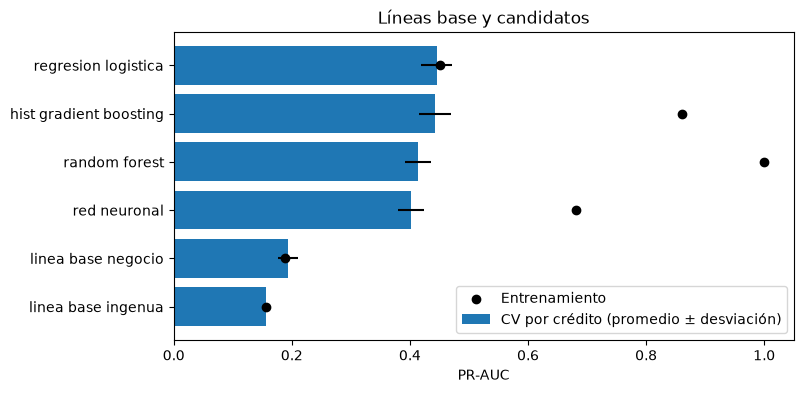

,modelo,familia,pr_auc_entrenamiento,pr_auc_cv_promedio,pr_auc_cv_desviacion,brecha,segundos_entrenamiento,learning_rate
2,regresion logistica,lineal regularizado,0.4510,0.4453,0.0265,0.0057,0.9345,NaN
4,hist gradient boosting,boosting,0.8611,0.4431,0.0272,0.4180,1.1165,0.100
3,random forest,bagging,1.0000,0.4132,0.0220,0.5868,1.5166,NaN
5,red neuronal,red neuronal,0.6812,0.4021,0.0216,0.2791,20.1623,0.001
1,linea base negocio,regla de negocio,0.1892,0.1931,0.0170,-0.0039,0.0000,NaN
0,linea base ingenua,linea base,0.1565,0.1565,0.0042,0.0000,0.0662,NaN


In [7]:
tabla = pd.DataFrame(resultados)[["modelo", "familia", "pr_auc_entrenamiento", "pr_auc_cv_promedio",
                                  "pr_auc_cv_desviacion", "brecha", "segundos_entrenamiento"]]
tabla["learning_rate"] = tabla["modelo"].map({"hist gradient boosting": 0.1, "red neuronal": 0.001})
tabla = tabla.sort_values("pr_auc_cv_promedio", ascending=False).round(4)

orden = tabla.sort_values("pr_auc_cv_promedio")
fig, eje = plt.subplots(figsize=(8, 4))
eje.barh(orden["modelo"], orden["pr_auc_cv_promedio"], xerr=orden["pr_auc_cv_desviacion"],
         label="CV por crédito (promedio ± desviación)")
eje.scatter(orden["pr_auc_entrenamiento"], orden["modelo"], color="black", zorder=3, label="Entrenamiento")
eje.set_xlabel("PR-AUC")
eje.set_title("Líneas base y candidatos")
eje.legend(loc="lower right")
plt.savefig("../docs/figuras/candidatos_resultados.png", bbox_inches="tight")
plt.show()

tabla

## 8. Prueba de un LLM mediante prompting (State of the Art)

Se prueba un LLM (Claude, en claude.ai) con *few-shot prompting*: se le dan 10 créditos resueltos del entrenamiento (5 que pagaron y 5 que no) y se le pide la probabilidad de pago de 40 créditos que no vio. No se entrena nada.

Las 40 filas salen del último pliegue de validación, no del conjunto de prueba, que se reserva para la evaluación final. Para comparar sobre **las mismas filas**, la regresión logística y el boosting se entrenan con los otros pliegues y predicen esas mismas 40 filas.

In [8]:
columnas_llm = ["dias_mora", "cuotas_mora", "valor_deuda_exigible", "capital_insoluto",
                "estado_operacion", "plazo_terminado", "compromiso_semana_previa", "gestionado_7d"]

idx_ent, idx_val = list(CV.split(X_ent, groups=grupos_ent))[-1]
X_pl_ent, y_pl_ent = X_ent.iloc[idx_ent], y_ent.iloc[idx_ent]
X_pl_val, y_pl_val = X_ent.iloc[idx_val], y_ent.iloc[idx_val]

ejemplos = pd.concat([X_pl_ent[y_pl_ent == 1].sample(5, random_state=42),
                      X_pl_ent[y_pl_ent == 0].sample(5, random_state=42)])
ejemplos = ejemplos[columnas_llm].assign(paga_7d=y_pl_ent.loc[ejemplos.index])
muestra = X_pl_val.sample(40, random_state=42)
y_muestra = y_pl_val.loc[muestra.index]

prompt = (
    "Eres analista de cobranzas. Cada fila es un crédito de auto en mora, con datos del cierre de hoy. "
    "paga_7d = 1 si el cliente paga al menos una cuota en los próximos 7 días.\n"
    "Columnas: dias_mora (días de atraso), cuotas_mora (cuotas vencidas), valor_deuda_exigible y "
    "capital_insoluto (en dólares), estado_operacion, plazo_terminado (1 = todas las cuotas ya vencieron), "
    "compromiso_semana_previa (1 = prometió pagar en la última semana), "
    "gestionado_7d (1 = será llamado en los próximos 7 días).\n\n"
    "Ejemplos resueltos:\n" + ejemplos.to_csv(index=False) +
    "\nEstima la probabilidad de que paga_7d = 1 para cada una de estas 40 filas. "
    "Responde SOLO con 40 números entre 0 y 1, uno por línea, en el mismo orden, sin texto adicional.\n\n" +
    muestra[columnas_llm].to_csv(index=False)
)

with open("../docs/prompt_llm.txt", "w") as archivo:
    archivo.write(prompt)
print("Positivos en la muestra:", y_muestra.sum(), "de", len(y_muestra))
print(prompt)

Positivos en la muestra: 6 de 40
Eres analista de cobranzas. Cada fila es un crédito de auto en mora, con datos del cierre de hoy. paga_7d = 1 si el cliente paga al menos una cuota en los próximos 7 días.
Columnas: dias_mora (días de atraso), cuotas_mora (cuotas vencidas), valor_deuda_exigible y capital_insoluto (en dólares), estado_operacion, plazo_terminado (1 = todas las cuotas ya vencieron), compromiso_semana_previa (1 = prometió pagar en la última semana), gestionado_7d (1 = será llamado en los próximos 7 días).

Ejemplos resueltos:
dias_mora,cuotas_mora,valor_deuda_exigible,capital_insoluto,estado_operacion,plazo_terminado,compromiso_semana_previa,gestionado_7d,paga_7d
17,1,317.14,2069.56,VENCIDO,0,0,1,1
61,2,1136.9,13035.33,NON ACCRUAL,0,0,0,1
20,1,518.36,9037.07,VENCIDO,0,1,1,1
27,1,518.61,15897.37,VENCIDO,0,0,1,1
15,1,489.9,14857.46,VENCIDO,0,0,1,1
974,33,10827.33,10550.02,NON ACCRUAL,0,0,0,0
83,3,1030.28,11067.51,NON ACCRUAL,0,0,0,0
1228,23,16125.38,9878.28,CASTIGADA,1,0,1,0


**Comparación sobre las mismas 40 filas.** La respuesta del LLM (40 probabilidades) se compara con la regla de negocio, la línea base ingenua y dos modelos (regresión logística e hist gradient boosting) entrenados con el mismo pliegue que vio el LLM. Se registra en MLflow como una corrida más, con el prompt y la respuesta guardados como artefactos, para que la prueba se pueda revisar y repetir.

In [9]:
respuesta_llm = """
0.80
0.03
0.12
0.70
0.05
0.06
0.10
0.88
0.03
0.55
0.05
0.55
0.30
0.08
0.55
0.05
0.88
0.35
0.60
0.03
0.07
0.40
0.72
0.78
0.10
0.75
0.03
0.12
0.10
0.75
0.03
0.60
0.78
0.04
0.80
0.08
0.50
0.40
0.40
0.05
"""
prob_llm = [float(x) for x in respuesta_llm.split()]
print("Números recibidos:", len(prob_llm))

comparacion = {"LLM (Claude, few-shot)": prob_llm,
               "linea base negocio": muestra["capital_insoluto"]}
for nombre, modelo in [("regresion logistica", LogisticRegression(max_iter=1000, random_state=42)),
                       ("hist gradient boosting", HistGradientBoostingClassifier(random_state=42))]:
    pipeline = Pipeline([("preparar", construir_preparacion()), ("modelo", modelo)])
    pipeline.fit(X_pl_ent, y_pl_ent)
    comparacion[nombre] = pipeline.predict_proba(muestra)[:, 1]

filas = [{"modelo": nombre, "pr_auc_40_filas": round(average_precision_score(y_muestra, puntajes), 4)}
         for nombre, puntajes in comparacion.items()]
filas.append({"modelo": "linea base ingenua", "pr_auc_40_filas": round(y_muestra.mean(), 4)})

with mlflow.start_run(run_name="llm few-shot"):
    mlflow.log_params({"modelo_llm": "Claude (claude.ai)", "ejemplos_few_shot": 10, "filas_evaluadas": 40,
                       "huella_datos": huella_datos, "validacion": "ultimo pliegue GroupKFold, 40 filas"})
    mlflow.set_tags({"fase": "candidato", "familia": "state of the art", "commit": commit})
    mlflow.log_metric("pr_auc_40_filas", average_precision_score(y_muestra, prob_llm))
    mlflow.log_text(prompt, "prompt_llm.txt")
    mlflow.log_text(respuesta_llm, "respuesta_llm.txt")

pd.DataFrame(filas).sort_values("pr_auc_40_filas", ascending=False)

Números recibidos: 40


,modelo,pr_auc_40_filas
3,hist gradient boosting,0.6586
2,regresion logistica,0.6197
0,"LLM (Claude, few-shot)",0.4139
1,linea base negocio,0.2181
4,linea base ingenua,0.1500


**Hallazgo: el LLM supera a las líneas base, pero los modelos entrenados le ganan con claridad, y no es viable para el uso diario.**
- **Evidencia:** sobre las mismas 40 filas, el LLM con 10 ejemplos obtiene PR-AUC de 0.414, frente a 0.218 de la regla de negocio y 0.150 de la línea base ingenua; la regresión logística (0.620) y el boosting (0.659) lo superan. Con solo 40 filas y 6 positivos, una predicción más o menos mueve bastante la métrica, así que estos números son indicativos, no definitivos.
- **Por qué no se elige, además del desempeño:**
  - **Privacidad:** con datos reales, enviar información de clientes a un proveedor externo no está permitido por la empresa; esta prueba solo es posible porque los datos son sintéticos y anonimizados.
  - **Costo y escala:** la lista diaria tiene unos 3,000 créditos en mora; cada pedido se cobra por tokens y viaja por la red, frente a milisegundos de un modelo local.
  - **Determinismo:** el mismo prompt puede dar probabilidades distintas en otra conversación; un modelo entrenado con `random_state` fijo siempre da el mismo resultado, lo que es necesario para que la lista sea reproducible y auditable.
  - **Explicabilidad:** no hay forma de saber qué variables usó el LLM para cada probabilidad.
- **Consecuencia:** el LLM no pasa al tuning. Queda registrado en MLflow (corrida `llm few-shot`, con el prompt y la respuesta) como evidencia de la comparación.